# Optimizing Mobile Clinic Stops in Rural Central Wisconsin
A maximal covering location model, written as a binary integer program (a type of MIP), in Pyomo with the CBC solver.

**Question:** a preventive-care outreach van (screenings, vaccinations, blood pressure and diabetes checks) will visit towns around Marshfield one day a week. With a fixed annual budget, which towns should host a stop so the most town residents live within a 25-minute drive of one?

The van complements existing clinics rather than replacing them; existing clinics and hospitals in these towns are not modeled. Populations count residents inside town limits (2020 Census incorporated places), not the surrounding townships.

*Hypothetical client: Marshfield Clinic. Not affiliated with Marshfield Clinic or Sanford Health. Populations are 2020 Census, drive times come from OSRM road routing, and costs are estimates built from public wage and mileage data.*

## 0. Setup

In [1]:
%%capture
import sys
import os

if 'google.colab' in sys.modules:
    !pip install idaes-pse --pre
    !idaes get-extensions --to ./bin
    os.environ['PATH'] += ':bin'

from pyomo.environ import *

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)  # show full town lists in tables

## 1. Inputs
Every assumption lives here. Change a value and rerun from this cell down.

In [3]:
REPO = "https://raw.githubusercontent.com/Aadil6696/rural-mobile-clinic-siting/refs/heads/main/"
TOWNS_CSV = REPO + "marshfield_mobile_clinic_towns.csv"   # town, pop2020, lat, lon
DRIVE_CSV = REPO + "town_drive_matrix.csv"                # origin, destination, drive_min, road_mi

HUB = "Marshfield"
COVERAGE_MIN = 25          # HRSA treats 30 min as the max for reasonable access; 25 leaves a buffer for winter roads and other unknown factors.
DRIVE_TIME_FACTOR = 0.79   # OSRM runs slow on rural roads; calibrated to Google Maps (Colby, Pittsville)

# Annual cost of one staffed stop day per week
CREW_WAGE = 63.45 + 45.93 + 23.41   # $/hr: NP + RN + MA, Wisconsin medians, BLS May 2025
BENEFITS = 1.30                     # assumption
CLINIC_HOURS = 8
MILEAGE = 0.725                     # $/mile, IRS 2026
OVERHEAD_K = 10                     # $K/yr per site: vehicle share, insurance, supplies (assumption)
NOISE = 0.10                        # +/-10% site-specific variation (assumption)
SEED = 42

BUDGET_K = 200                      # main scenario, $K/yr
BUDGETS_K = range(0, 451, 25)       # budget scenarios

## 2. Data
Load towns and the drive matrix, calibrate drive times, and build the coverage matrix: `a[i, j] = 1` if town *i* is within `COVERAGE_MIN` of town *j*.

In [4]:
towns = pd.read_csv(TOWNS_CSV).set_index("town")
drive = pd.read_csv(DRIVE_CSV)
TOWNS = towns.index.tolist()

def square(col):
    m = drive.pivot(index="origin", columns="destination", values=col).loc[TOWNS, TOWNS]
    return np.maximum(m, m.T)  # routing differs slightly by direction; keep the slower one

drive_min = (square("drive_min") * DRIVE_TIME_FACTOR).round(1)
road_mi = square("road_mi")
a = (drive_min <= COVERAGE_MIN).astype(int)

towns["min_from_hub"] = drive_min[HUB]
towns["hub_covered"] = a[HUB] == 1
TARGET_POP = towns.loc[~towns.hub_covered, "pop2020"].sum()  # target residents: beyond the hub's reach

print(f"Hub already covers: {towns.index[towns.hub_covered].tolist()}")
print(f"Target residents (beyond {COVERAGE_MIN} min of {HUB}): {TARGET_POP:,}")

Hub already covers: ['Marshfield', 'Auburndale', 'Spencer', 'Stratford', 'Pittsville']
Target residents (beyond 25 min of Marshfield): 23,128


## 3. Site costs
Annual cost of one weekly stop day in town *j* ($K): crew time on site and on the road, vehicle mileage, and overhead, with ±10% site variation.

cost = [52 × (crew/hr × (clinic hours + round-trip drive hours) + round-trip miles × mileage) / 1000 + overhead] × noise

Cross-check: the Advisory Board puts the average mobile clinic at about &#36;450K a year, roughly &#36;90K per weekly stop day.

In [5]:
crew_hr = CREW_WAGE * BENEFITS
np.random.seed(SEED)
noise = np.random.uniform(1 - NOISE, 1 + NOISE, len(towns))

towns["cost_k"] = (52 * (crew_hr * (CLINIC_HOURS + 2 * towns.min_from_hub / 60)
                         + 2 * road_mi[HUB] * MILEAGE) / 1000 + OVERHEAD_K) * noise
towns["cost_k"] = towns.cost_k.round(0)
towns.loc[HUB, "cost_k"] = 0  # hub already operates

towns.loc[towns.index != HUB, ["pop2020", "min_from_hub", "cost_k"]].sort_values("cost_k")

,pop2020,min_from_hub,cost_k
town,,,
Vesper,513,28.0,84.0
Pittsville,813,24.3,84.0
Granton,381,25.1,85.0
Edgar,1439,34.4,85.0
Dorchester,849,37.3,90.0
Athens,1059,39.6,90.0
Stratford,1581,17.9,90.0
Spencer,1818,14.1,91.0
Colby,1952,26.7,93.0


## 4. Model
All decisions are yes/no, so this is a binary integer program, a special case of a MIP.

**Decision variables (binary):** y<sub>j</sub> = 1 if a stop opens in town *j*; z<sub>i</sub> = 1 if town *i* is covered.

**Objective:** maximize residents covered, Σ pop<sub>i</sub> · z<sub>i</sub>

**Constraints**
1. Coverage: z<sub>i</sub> ≤ Σ<sub>j</sub> a<sub>ij</sub> · y<sub>j</sub> (covered only if an open stop is within range)
2. Budget: Σ<sub>j</sub> cost<sub>j</sub> · y<sub>j</sub> ≤ budget
3. Hub: y<sub>Marshfield</sub> = 1

In [6]:
def solve(budget_k):
    model = ConcreteModel()
    model.y = Var(TOWNS, domain=Binary)
    model.z = Var(TOWNS, domain=Binary)

    model.Objective = Objective(expr=sum(towns.pop2020[i] * model.z[i] for i in TOWNS), sense=maximize)

    model.coverage = ConstraintList()
    for i in TOWNS:
        model.coverage.add(expr=model.z[i] <= sum(a.loc[i, j] * model.y[j] for j in TOWNS))
    model.budget = Constraint(expr=sum(towns.cost_k[j] * model.y[j] for j in TOWNS) <= budget_k)
    model.hub = Constraint(expr=model.y[HUB] == 1)

    results = SolverFactory("cbc").solve(model)
    assert results.solver.termination_condition == TerminationCondition.optimal, "CBC did not find an optimal solution"
    return [j for j in TOWNS if j != HUB and value(model.y[j]) > 0.5]

def covered(stops):
    return a[[HUB] + stops].max(axis=1) == 1

def pct_reached(stops):
    reached = covered(stops) & ~towns.hub_covered
    return towns.pop2020[reached].sum() / TARGET_POP

## 5. Results at the main budget

In [7]:
stops = solve(BUDGET_K)
spent = towns.cost_k[stops].sum()
print(f"Stops: {stops}  |  Cost: ${spent:.0f}K of ${BUDGET_K}K  |  Reached: {pct_reached(stops):.0%} of {TARGET_POP:,}")

# Assign each newly covered town to its nearest open stop
new = towns.index[covered(stops) & ~towns.hub_covered]
towns["served_by"] = towns.index.map(lambda t: HUB if towns.hub_covered[t] else None)
towns.loc[new, "served_by"] = drive_min.loc[new, stops].idxmin(axis=1)

(towns.loc[new].groupby("served_by")
      .agg(towns=("pop2020", lambda s: ", ".join(s.index)), residents=("pop2020", "sum"))
      .join(towns.cost_k.rename("cost_k")))

Stops: ['Abbotsford', 'Greenwood']  |  Cost: $198K of $200K  |  Reached: 86% of 23,128


,towns,residents,cost_k
served_by,,,
Abbotsford,"Colby, Abbotsford, Edgar, Dorchester, Athens, Owen, Withee, Medford, Thorp",15140,96.0
Greenwood,"Loyal, Neillsville, Greenwood",4645,102.0


## 6. Benchmark: biggest towns first
A common rule of thumb: rank towns by population and open stops in that order while the budget allows.

In [8]:
def biggest_first(budget_k):
    picks, spent = [], 0
    for t in towns.drop(HUB).sort_values("pop2020", ascending=False).index:
        if spent + towns.cost_k[t] <= budget_k:
            picks.append(t)
            spent += towns.cost_k[t]
    return picks

base = biggest_first(BUDGET_K)
print(f"Biggest first: {base}  ->  {pct_reached(base):.0%} reached")
print(f"Optimized:     {stops}  ->  {pct_reached(stops):.0%} reached")

Biggest first: ['Medford', 'Nekoosa']  ->  54% reached
Optimized:     ['Abbotsford', 'Greenwood']  ->  86% reached


## 7. Budget scenarios
Re-solve across budgets to show how coverage grows with spend.

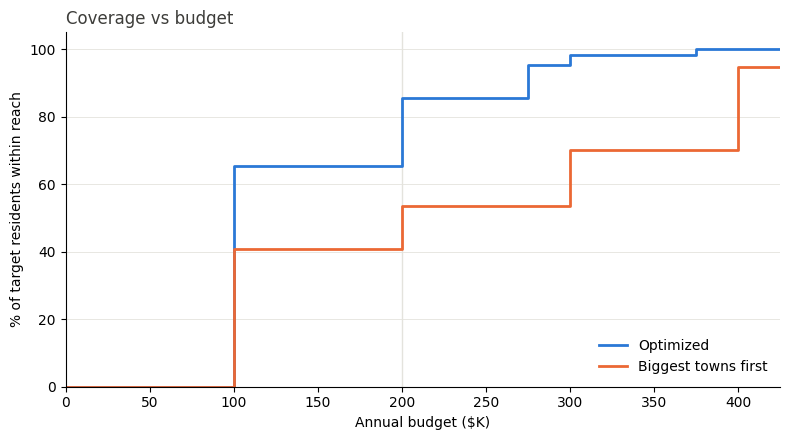

,optimized,biggest_first
budget_k,,
100,65%,41%
200,86%,54%
300,98%,70%


In [9]:
curve = pd.DataFrame([
    {"budget_k": b, "optimized": pct_reached(solve(b)), "biggest_first": pct_reached(biggest_first(b))}
    for b in BUDGETS_K
])

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#3d3d3a", "#e4e3dd"
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(curve.budget_k, curve.optimized * 100, where="post", color=BLUE, lw=2, label="Optimized")
ax.step(curve.budget_k, curve.biggest_first * 100, where="post", color=ORANGE, lw=2, label="Biggest towns first")
ax.axvline(BUDGET_K, color=GRID, lw=1, zorder=0)
ax.set(xlabel="Annual budget ($K)", ylabel="% of target residents within reach", xlim=(0, 425), ylim=(0, 105))
ax.set_title("Coverage vs budget", loc="left", color=INK)
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("fig_budget_curve.png", dpi=200)
plt.show()

curve.set_index("budget_k").loc[[100, 200, 300]].style.format("{:.0%}")

## 8. Map of the recommended network

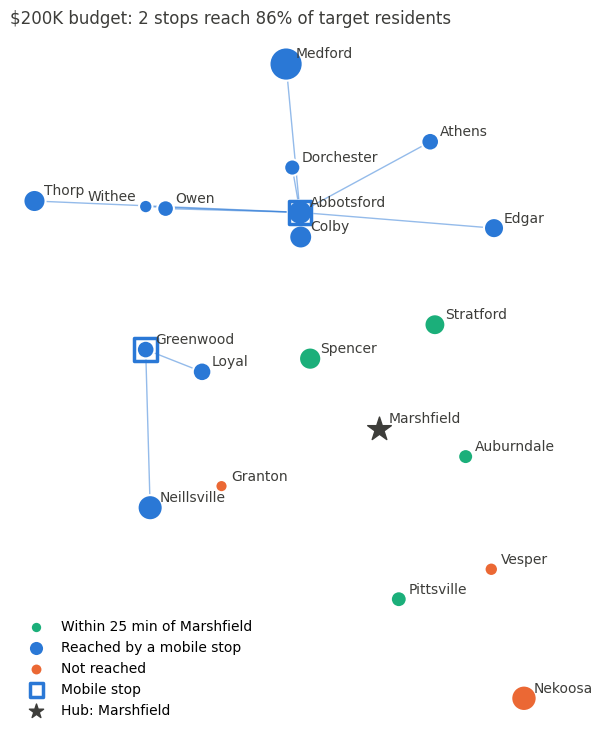

In [10]:
GREEN = "#1baf7a"
fig, ax = plt.subplots(figsize=(8, 7.5))

# Lines from each newly covered town to its stop
for t in new:
    s = towns.served_by[t]
    ax.plot([towns.lon[t], towns.lon[s]], [towns.lat[t], towns.lat[s]], color=BLUE, lw=1, alpha=0.5, zorder=1)

groups = [
    (towns.hub_covered & (towns.index != HUB), GREEN, f"Within {COVERAGE_MIN} min of {HUB}"),
    (towns.index.isin(new), BLUE, "Reached by a mobile stop"),
    (~covered(stops), ORANGE, "Not reached"),
]
for mask, color, label in groups:
    g = towns[mask]
    ax.scatter(g.lon, g.lat, s=g.pop2020 / 8 + 30, color=color, edgecolor="white", lw=1.5, label=label, zorder=2)

ax.scatter(towns.lon[stops], towns.lat[stops], s=260, marker="s", facecolor="none", edgecolor=BLUE, lw=2.5,
           label="Mobile stop", zorder=3)
ax.scatter(towns.lon[HUB], towns.lat[HUB], s=320, marker="*", color=INK, label=f"Hub: {HUB}", zorder=3)

for t, r in towns.iterrows():
    # put the label on the left when a neighbor sits just to the right
    left = ((towns.lon > r.lon) & (towns.lon - r.lon < 0.08) & ((towns.lat - r.lat).abs() < 0.03)).any()
    ax.annotate(t, (r.lon, r.lat), xytext=(-7 if left else 7, 4), textcoords="offset points",
                ha="right" if left else "left", fontsize=10, color=INK)

ax.set_aspect(1 / np.cos(np.radians(towns.lat.mean())))  # equal miles east-west and north-south
ax.set_title(f"${BUDGET_K}K budget: {len(stops)} stops reach {pct_reached(stops):.0%} of target residents",
             loc="left", color=INK)
ax.set_xticks([]); ax.set_yticks([])
ax.spines[:].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=10, markerscale=0.6)
plt.tight_layout()
plt.savefig("fig_map.png", dpi=200)
plt.show()

## 9. Takeaways
- At the default inputs (&#36;200K budget, 25-minute standard), stops in **Abbotsford and Greenwood** bring **86%** of target residents within 25 minutes, versus **54%** for the biggest-towns-first rule.
- Abbotsford is a small town, but it sits in the middle of the northern cluster and reaches 9 towns. Population alone would never pick it.
- The plan is robust to the random site-cost variation: the same two stops are chosen in 28 of 30 random draws.
- Main limitations: one crew day per stop regardless of reach, residents outside town limits not counted, and existing clinics not modeled.